Do emotional and neutral recall rates vary differently across study positions? This procedure compares category-specific SPCs within the same mixed lists. The example uses recorded recalls from the war-photo-recall experiment.

## Parameters and setup

The tagged **parameters** cell contains the defaults for one run. Edit them here, or supply replacements through Quarto or Papermill. The following cell imports the tools and prepares paths from the resulting values.

Give independent jobs different `output_dir` values to keep their results separate. The discussion and saved results below describe the default example.

In [1]:
#| code-summary: "Set the parameters for this run"

data_path = "data/Dupertuys2026.h5"
output_dir = "results/cat_spc"

confidence_level = 0.95
category_values = [-1, 0]
category_labels = ["Emotional", "Neutral"]
plot_seed = 0  # NumPy seed for bootstrap displays.


In [ ]:
#| code-summary: "Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "3f0607f5cbbc56afab915577a15ede81e1398c12"
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
    ])
    from jaxcmr.colab import fetch_inputs

    fetch_inputs([data_path], revision=revision)


In [2]:
#| code-summary: "Import packages and the category SPC plotter"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp
from jaxcmr.helpers import load_data

plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 120})

from jaxcmr.analyses.cat_spc import plot_cat_spc

# Resolve paths and derived settings after parameter overrides.
data_path = Path(data_path)
output_dir = Path(output_dir)
np.random.seed(plot_seed)
output_dir.mkdir(parents=True, exist_ok=True)

## Select valid category observations

The numerator counts recalled items from a category at a position. The denominator counts
occasions on which a valid item from that category was studied at that position. It is not the
total number of mixed lists. The temporary category field below marks padded positions with a
value outside the requested categories; it does not alter the input file.

In [3]:
#| code-summary: "Select mixed lists and exclude padding from categories"

data = load_data(str(data_path))
list_type = np.asarray(data["list_type"]).ravel()
subjects = np.asarray(data["subject"]).ravel()
presentations = np.asarray(data["pres_itemnos"])
complete = np.all(presentations > 0, axis=1)
conditions = {1: "Mixed", 2: "Pure emotional", 3: "Pure neutral"}
print(f"Loaded {len(list_type)} lists from {len(np.unique(subjects))} participants.")

trial_mask = jnp.asarray(list_type == 1)
print(f"Selected {int(trial_mask.sum())} mixed lists.")

data = dict(data)
data["analysis_category"] = jnp.where(data["pres_itemnos"] > 0, data["valence"], 99)

Loaded 492 lists from 123 participants.
Selected 246 mixed lists.


## Calculate and plot

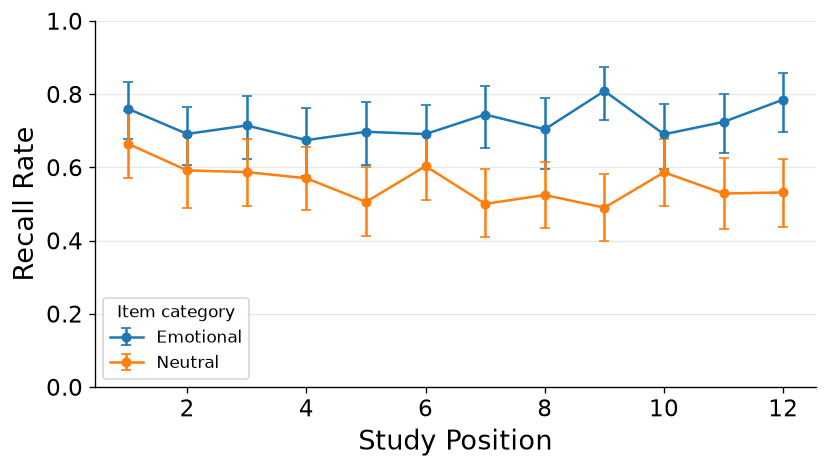

In [4]:
#| code-summary: "Plot and save category serial position curves"

fig, ax = plt.subplots()
plot_cat_spc(data, trial_mask, category_field="analysis_category", category_values=category_values,
             labels=category_labels, contrast_name="Item category",
             confidence_level=confidence_level, axis=ax)
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(output_dir / "category_spc.png", dpi=160)
plt.show()

## Interpret and adapt

The emotional curve is above the neutral curve at every study position in this display. Read this alongside the overall SPC. A separation describes category-dependent recall in these observations; it does not locate an effect uniquely in encoding or retrieval.

To use another experiment, change `data_path` and the selection settings, then check that
the fields above have the same meanings. Change `output_dir` to keep another run's results.
The figure is saved as `results/cat_spc/category_spc.png`. No repository checkout is required.